# 01 - Exploration d'Allociné et baseline TF-IDF

Ce projet compare trois approches de classification de sentiment sur des critiques de films en
français ([Allociné](https://huggingface.co/datasets/tblard/allocine), 160 000 critiques
d'entraînement, 20 000 en validation, 20 000 en test) :

1. **Baseline classique** : TF-IDF + régression logistique *(ce notebook)*
2. **Transformer fine-tuné** : CamemBERT ou DistilBERT *(notebook 02)*
3. **LLM en few-shot**, sans entraînement *(notebook 03)*

L'objectif n'est pas seulement de maximiser la précision, mais de mesurer ce que chaque
approche coûte (temps d'entraînement, latence, taille du modèle) pour juger du moment où un
modèle plus lourd se justifie réellement.

Ce premier notebook couvre l'exploration des données puis la baseline, qui sert de point de
référence pour toutes les comparaisons suivantes.


## 1. Imports et configuration

In [1]:
# Dépendances : pip install datasets scikit-learn pandas matplotlib joblib

import json
import textwrap
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.pipeline import Pipeline

SEED = 42
np.random.seed(SEED)

# Dossier de sortie : les métriques de chaque approche y sont enregistrées
# pour alimenter le tableau comparatif final.
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

c:\Users\clement\anaconda3\envs\safe1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Chargement des données

Le dataset est distribué au format Parquet sur le Hugging Face Hub, avec trois découpages
prédéfinis (`train`, `validation`, `test`). Ce découpage officiel est conservé tel quel : il
garantit que les résultats restent comparables à ceux publiés pour ce corpus.

Le label vaut 0 pour une critique négative et 1 pour une critique positive.

In [2]:
ds = load_dataset("tblard/allocine")

train_df = ds["train"].to_pandas()
val_df = ds["validation"].to_pandas()
test_df = ds["test"].to_pandas()

splits = {"train": train_df, "validation": val_df, "test": test_df}

for name, df in splits.items():
    share_pos = df["label"].mean()
    print(f"{name:<11} {len(df):>8,} critiques | {share_pos:.1%} positives")

c:\Users\clement\anaconda3\envs\safe1\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\clement\.cache\huggingface\hub\datasets--tblard--allocine. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\clement\anaconda3\envs\safe1\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `hug

train        160,000 critiques | 50.4% positives
validation    20,000 critiques | 49.0% positives
test          20,000 critiques | 48.0% positives


In [3]:
train_df.head()

,review,label
0,Si vous cherchez du cinéma abrutissant à tous ...,0
1,"Trash, re-trash et re-re-trash...! Une horreur...",0
2,"Et si, dans les 5 premières minutes du film, l...",0
3,Mon dieu ! Quelle métaphore filée ! Je suis ab...,0
4,"Premier film de la saga Kozure Okami, ""Le Sabr...",1


## 3. Exploration

### Longueur des critiques

La longueur des textes conditionne un choix technique important pour la suite : les
transformers imposent une longueur maximale de séquence (512 tokens pour CamemBERT), et au-delà
le texte est tronqué. Connaître la distribution permet de savoir quelle part du corpus serait
concernée. Le corpus ne contient que des critiques de moins de 2 000 caractères, ce qui limite
déjà le problème.

In [4]:
for df in splits.values():
    df["n_chars"] = df["review"].str.len()
    df["n_words"] = df["review"].str.split().str.len()

train_df[["n_chars", "n_words"]].describe().round(1)

,n_chars,n_words
count,160000.0,160000.0
mean,542.5,91.3
std,451.1,75.4
min,3.0,1.0
25%,196.0,34.0
50%,389.0,66.0
75%,771.0,130.0
max,2000.0,384.0


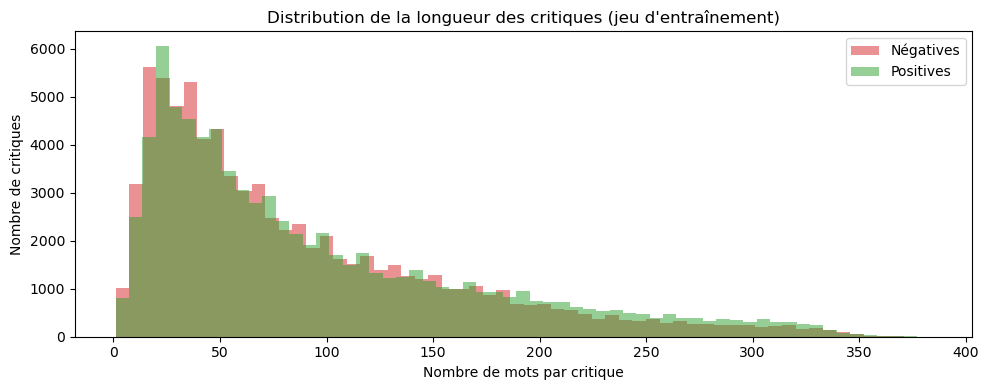

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))

for label, name, color in [(0, "Négatives", "tab:red"), (1, "Positives", "tab:green")]:
    ax.hist(
        train_df.loc[train_df["label"] == label, "n_words"],
        bins=60, alpha=0.5, color=color, label=name,
    )

ax.set_xlabel("Nombre de mots par critique")
ax.set_ylabel("Nombre de critiques")
ax.set_title("Distribution de la longueur des critiques (jeu d'entraînement)")
ax.legend()
plt.tight_layout()
plt.show()

### Aperçu de quelques critiques

Lire des exemples bruts reste la meilleure façon de repérer des difficultés que les statistiques
ne montrent pas : ironie, négations, critiques nuancées.

In [6]:
for label, name in [(0, "NÉGATIVES"), (1, "POSITIVES")]:
    print(f"===== {name} =====")
    sample = train_df[train_df["label"] == label].sample(3, random_state=SEED)
    for review in sample["review"]:
        print(textwrap.fill(review[:400], width=100))
        print("-" * 100)

===== NÉGATIVES =====
Malgré une scène d'entrée superbe, la mise en scène originale et la présence de Francois Damien qui
est toujours hilarant et bien sur celle de j-c, ce film m'a decu. Il ne se passe pas grand chose, et
j'ai fini par m'ennuyer.
----------------------------------------------------------------------------------------------------
Le pictural Julian Schnabel était-il le cinéaste le plus indiqué pour tourner cette ode à la paix
entre israéliens et palestiniens?On peut en douter tant son film se révèle sirupeux,didactique à
l'extrême et trop conciliant.Il simplifie bêtement les enjeux,alors que conflit de 60 ans est
justement l'un des plus complexes qui soient.Dans "Miral",on suit 3 générations de femmes
palestiniennes,qui te
----------------------------------------------------------------------------------------------------
Le premier film de Nossiter (Sunday) est une merveille. Je ne peux pas en dire autant du second. La
délicatesse et la justesse du regard du premier l

## 4. Baseline : TF-IDF + régression logistique

### Principe

TF-IDF transforme chaque critique en un vecteur creux où chaque dimension correspond à un mot
(ou une paire de mots consécutifs), pondéré par son importance : fréquent dans la critique mais
rare dans le corpus. Une régression logistique apprend ensuite un poids par terme, ce qui rend
le modèle entièrement interprétable.

Cette approche ignore l'ordre des mots au-delà des bigrammes et ne capture pas le sens
contextuel. Elle reste néanmoins un point de comparaison indispensable : si un transformer ne
la dépasse que de quelques points, le surcoût de calcul doit être justifié.

### Réglage de l'hyperparamètre C

C contrôle la régularisation (plus C est petit, plus le modèle est contraint). La valeur est
choisie sur le jeu de **validation**, afin que le jeu de test ne soit utilisé qu'une seule fois,
pour l'évaluation finale.

In [7]:
def build_pipeline(C):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),   # mots seuls et paires de mots consécutifs
            min_df=3,             # termes présents dans au moins 3 critiques
            max_features=300_000,
            sublinear_tf=True,    # atténue l'effet des répétitions d'un même mot
        )),
        ("clf", LogisticRegression(C=C, max_iter=1000)),
    ])


val_scores = {}
for C in [0.5, 1, 4, 10]:
    pipe = build_pipeline(C).fit(train_df["review"], train_df["label"])
    val_scores[C] = accuracy_score(val_df["label"], pipe.predict(val_df["review"]))
    print(f"C = {C:<4} -> accuracy validation : {val_scores[C]:.4f}")

best_C = max(val_scores, key=val_scores.get)
print(f"\nMeilleure valeur retenue : C = {best_C}")

C = 0.5  -> accuracy validation : 0.9351
C = 1    -> accuracy validation : 0.9383
C = 4    -> accuracy validation : 0.9412
C = 10   -> accuracy validation : 0.9447

Meilleure valeur retenue : C = 10


### Entraînement final et évaluation sur le jeu de test

Le temps d'entraînement est mesuré à cette étape, car il fait partie des critères de
comparaison avec les approches suivantes.

In [8]:
start = time.perf_counter()
baseline = build_pipeline(best_C).fit(train_df["review"], train_df["label"])
train_time_s = time.perf_counter() - start

y_pred = baseline.predict(test_df["review"])
accuracy = accuracy_score(test_df["label"], y_pred)
f1 = f1_score(test_df["label"], y_pred)

print(f"Temps d'entraînement : {train_time_s:.1f} s")
print(f"Accuracy (test)      : {accuracy:.4f}")
print(f"F1-score (test)      : {f1:.4f}\n")
print(classification_report(
    test_df["label"], y_pred, target_names=["négative", "positive"], digits=4
))

Temps d'entraînement : 29.0 s
Accuracy (test)      : 0.9446
F1-score (test)      : 0.9425

              precision    recall  f1-score   support

    négative     0.9501    0.9430    0.9466     10408
    positive     0.9387    0.9463    0.9425      9592

    accuracy                         0.9446     20000
   macro avg     0.9444    0.9447    0.9445     20000
weighted avg     0.9446    0.9446    0.9446     20000



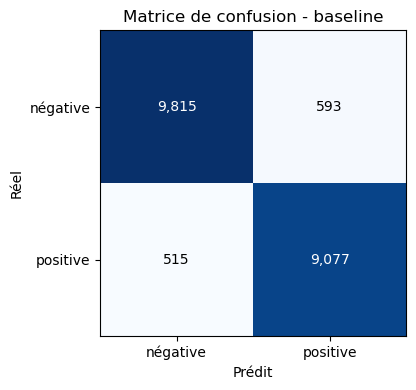

In [9]:
cm = confusion_matrix(test_df["label"], y_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["négative", "positive"])
ax.set_yticks([0, 1], ["négative", "positive"])
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title("Matrice de confusion - baseline")

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

## 5. Coût d'inférence

La précision ne suffit pas à comparer des approches : en production, la latence par requête et
la taille du modèle déterminent le matériel nécessaire. La latence est mesurée ici sur des
prédictions unitaires, qui correspondent à l'usage d'une API (une critique à la fois), et non
sur un traitement par lots, qui flatterait artificiellement les chiffres, mais qui resterais une stratégie fonctionelle suivent les attentes.

In [10]:
sample_reviews = test_df["review"].sample(200, random_state=SEED).tolist()

# Une première prédiction écarte le coût d'initialisation éventuel
baseline.predict([sample_reviews[0]])

start = time.perf_counter()
for review in sample_reviews:
    baseline.predict([review])
latency_ms = (time.perf_counter() - start) / len(sample_reviews) * 1000

model_path = RESULTS_DIR / "baseline_tfidf_logreg.joblib"
joblib.dump(baseline, model_path)
size_mb = model_path.stat().st_size / 1e6

print(f"Latence moyenne : {latency_ms:.2f} ms par critique")
print(f"Taille du modèle : {size_mb:.1f} Mo")

Latence moyenne : 0.55 ms par critique
Taille du modèle : 14.8 Mo


## 6. Interprétabilité

Un avantage propre à la régression logistique : les coefficients se lisent directement. Les
termes dont le poids est le plus élevé (ou pour l'opposer, le plus faible) sont ceux qui tirent la
prédiction vers « positif » (ducoup vers « négatif »). Cette transparence n'existe pas avec un
transformer, et constitue un critère à mettre dans la balance lors de la comparaison finale.

In [11]:
vectorizer = baseline.named_steps["tfidf"]
classifier = baseline.named_steps["clf"]

terms = np.array(vectorizer.get_feature_names_out())
order = np.argsort(classifier.coef_[0])

print("Termes les plus négatifs :", ", ".join(terms[order[:15]]))
print("\nTermes les plus positifs :", ", ".join(terms[order[-15:][::-1]]))

Termes les plus négatifs : ennui, ennuyeux, déception, plv, navet, décevant, mauvais, intérêt, ridicule, médiocre, nul, on ennuie, raté, éviter, plat

Termes les plus positifs : magnifique, excellent, superbe, beau film, merveille, sublime, parfaitement, ne ennuie, génial, pas mal, parfait, bravo, bijou, bon film, remarquable


## 7. Analyse d'erreurs

Les erreurs commises avec une forte confiance sont les plus instructives : elles révèlent les
limites structurelles du modèle plutôt que des cas ambigus. Elles serviront de cas de test pour
comparer le comportement des approches suivantes sur les mêmes exemples.

In [12]:
proba_pos = baseline.predict_proba(test_df["review"])[:, 1]

errors = test_df.assign(pred=y_pred, proba_pos=proba_pos)
errors = errors[errors["pred"] != errors["label"]].copy()

# Confiance du modèle dans sa (mauvaise) prédiction
errors["confidence"] = np.where(errors["pred"] == 1, errors["proba_pos"], 1 - errors["proba_pos"])

print(f"Erreurs totales : {len(errors):,} sur {len(test_df):,} ({len(errors) / len(test_df):.1%})\n")

for _, row in errors.sort_values("confidence", ascending=False).head(5).iterrows():
    truth = "positive" if row["label"] == 1 else "négative"
    print(f"[Réel : {truth} | confiance dans l'erreur : {row['confidence']:.0%}]")
    print(textwrap.fill(row["review"][:500], width=100))
    print("-" * 100)

Erreurs totales : 1,108 sur 20,000 (5.5%)

[Réel : positive | confiance dans l'erreur : 100%]
J'ai été très déçu par "Les fils de l'Homme", car il avait tout pour être bon : un bon réalisateur,
des bons acteurs ( Clive Owen et Michael Caine en s'en sortent pas trop mal, et Julianne Moore ne
tient tellement pas longtemps que l'on se demande tout le film si elle va revenir d'entre les
morts... ), une bonne idée de départ ( dans une Angleterre raciste, stérile et immorale, ils vont
tenter de sauver une noire enceinte... ) Mais cette bonne idée de départ va vite dégénérer dans un
grand n'imp
----------------------------------------------------------------------------------------------------
[Réel : positive | confiance dans l'erreur : 100%]
Un film si mauvais que ca en devient cosmique. Tout est raté dans ce film complêtement débil, les
dialogues sont mauvais, la mise en scène est affligeante, les acteurs sont ratés, le doublage est
pathétique, le scénario n'a aucun sens, les effets spécia

## 8. Sauvegarde des résultats

Les métriques sont enregistrées dans un fichier JSON, relu par le notebook de comparaison final
pour construire le tableau récapitulatif des trois approches.

In [13]:
results = {
    "model": "TF-IDF + régression logistique",
    "accuracy": round(accuracy, 4),
    "f1": round(f1, 4),
    "train_time_s": round(train_time_s, 1),
    "latency_ms": round(latency_ms, 2),
    "size_mb": round(size_mb, 1),
    "hardware": "CPU",
}

with open(RESULTS_DIR / "baseline.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

results

{'model': 'TF-IDF + régression logistique',
 'accuracy': 0.9446,
 'f1': 0.9425,
 'train_time_s': 29.0,
 'latency_ms': 0.55,
 'size_mb': 14.8,
 'hardware': 'CPU'}

## Synthèse et suite

La baseline fixe le niveau à dépasser. Pour mémoire, le modèle de référence publié avec le
corpus (un BERT français) atteint 97,4 % d'accuracy sur le jeu de test : l'écart entre cette
valeur et celle de la baseline mesure ce que le fine-tuning peut réellement apporter ici.

**Notebook 02** : fine-tuning d'un transformer français (sur GPU), avec les
mêmes métriques de coût pour une comparaison équitable.
